In [1]:
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.cm import get_cmap
from scipy.interpolate import interp1d
from scipy.signal import find_peaks, butter, filtfilt

In [2]:
def extract_envelopes(signal, peak_distance=None, smooth_cutoff_freq=None, sampling_freq=1.0):
    """
    Extracts the upper (max) and lower (min) envelopes of an oscillating signal.

    Parameters:
    - signal: np.ndarray
    - peak_distance: int or None — minimum distance between peaks (indices).
                     If None, auto-detected from dominant FFT frequency.
    - smooth_cutoff_freq: float or None — low-pass cutoff for smoothing the envelopes.
    - sampling_freq: float — sampling frequency (for FFT detection and filter design).

    Returns:
    - upper_envelope, lower_envelope: np.ndarray, same length as signal.
    """
    if not isinstance(signal, np.ndarray):
        signal = np.array(signal)

    indices = np.arange(len(signal))

    if peak_distance is None:
        fft_vals = np.fft.fft(signal)
        freqs = np.fft.fftfreq(len(signal), 1 / sampling_freq)
        positive_freq_idx = freqs > 0
        if np.any(positive_freq_idx):
            idx = np.argmax(np.abs(fft_vals[positive_freq_idx]))
            dominant_freq = freqs[positive_freq_idx][idx]
            if dominant_freq > 0:
                period_samples = sampling_freq / dominant_freq
                peak_distance = int(period_samples / 2)
            else:
                peak_distance = 10
        else:
            peak_distance = 10

    peak_distance = max(1, peak_distance)

    max_peaks, _ = find_peaks(signal, distance=peak_distance)
    min_peaks, _ = find_peaks(-signal, distance=peak_distance)

    if len(max_peaks) > 1:
        # Use edge-value fill instead of extrapolation to avoid divergence at boundaries
        upper_interp = interp1d(indices[max_peaks], signal[max_peaks],
                                kind='linear', bounds_error=False,
                                fill_value=(signal[max_peaks[0]], signal[max_peaks[-1]]))
        upper_envelope = upper_interp(indices)
    else:
        upper_envelope = np.full_like(signal, np.max(signal) if len(signal) > 0 else np.nan)

    if len(min_peaks) > 1:
        lower_interp = interp1d(indices[min_peaks], signal[min_peaks],
                                kind='linear', bounds_error=False,
                                fill_value=(signal[min_peaks[0]], signal[min_peaks[-1]]))
        lower_envelope = lower_interp(indices)
    else:
        lower_envelope = np.full_like(signal, np.min(signal) if len(signal) > 0 else np.nan)

    # Guarantee upper >= lower everywhere (prevents negative amplitude)
    upper_envelope = np.maximum(upper_envelope, lower_envelope)

    if smooth_cutoff_freq is not None:
        nyq = 0.5 * sampling_freq
        normal_cutoff = smooth_cutoff_freq / nyq
        b, a = butter(3, normal_cutoff, btype='low', analog=False)
        upper_envelope = filtfilt(b, a, upper_envelope)
        lower_envelope = filtfilt(b, a, lower_envelope)

    return upper_envelope, lower_envelope


def find_wavepacket_envelope(t, x, method='peaks'):
    """
    Find the upper and lower envelopes of an oscillating wavepacket.

    Parameters:
    - t: array-like, time (or index) array
    - x: array-like, signal
    - method: 'peaks' (cubic interpolation between local extrema)
              or 'hilbert' (analytic signal magnitude)

    Returns: t_envelope, upper_envelope, lower_envelope
    """
    t = np.asarray(t)
    x = np.asarray(x)

    if method == 'peaks':
        peaks_max, _ = find_peaks(x)
        peaks_min, _ = find_peaks(-x)

        peaks_max = np.unique(np.concatenate([[0], peaks_max, [len(x)-1]]))
        peaks_min = np.unique(np.concatenate([[0], peaks_min, [len(x)-1]]))

        upper_interp = interp1d(t[peaks_max], x[peaks_max],
                                kind='cubic', fill_value='extrapolate')
        lower_interp = interp1d(t[peaks_min], x[peaks_min],
                                kind='cubic', fill_value='extrapolate')

        return t, upper_interp(t), lower_interp(t)

    elif method == 'hilbert':
        from scipy.signal import hilbert
        amp = np.abs(hilbert(x))
        return t, amp, -amp

    else:
        raise ValueError("method must be 'peaks' or 'hilbert'")

In [3]:
def envelope_trajectory(P_cv, downsample=1000, smooth_cutoff_freq=None, plot_subsample=500):
    """
    Compute amplitude and average trajectories via oscillation envelope detection.

    1. Downsample P_cv by `downsample` for speed (100M -> ~100k points).
    2. Auto-detect oscillation peak spacing via FFT.
    3. Interpolate upper/lower envelopes between peaks.
    4. amplitude = (upper - lower) / 2   [clipped to >= 0]
       average   = (upper + lower) / 2
    5. Subsample by `plot_subsample` to keep ~200 trajectory points.

    Parameters
    ----------
    P_cv : np.ndarray
        Raw pressure time series.
    downsample : int
        Stride for initial downsampling (default 1000).
    smooth_cutoff_freq : float or None
        If given, applies a low-pass Butterworth filter to the envelopes
        (frequency in units of the downsampled index, i.e. 0 < f < 0.5).
        A value around 0.001–0.01 smooths envelope wiggles while
        preserving the slow trend.
    plot_subsample : int
        Further stride applied after envelope extraction (default 500).

    Returns
    -------
    idx   : np.ndarray  — sample index (proxy for time)
    avg   : np.ndarray  — (upper + lower) / 2  (Pa)
    amp   : np.ndarray  — (upper - lower) / 2  (Pa), always >= 0
    """
    P_ds = P_cv[::downsample].astype(float)
    idx_ds = np.arange(len(P_ds), dtype=float)

    upper, lower = extract_envelopes(
        P_ds,
        sampling_freq=1.0,           # index units; FFT auto-detects peak spacing
        smooth_cutoff_freq=smooth_cutoff_freq,
    )

    avg = (upper + lower) / 2.0
    amp = np.maximum((upper - lower) / 2.0, 0.0)  # clip: amplitude is non-negative

    sl = slice(None, None, plot_subsample)
    return idx_ds[sl], avg[sl], amp[sl]

In [4]:
# ---- Configuration ----
downsample     = 1000   # stride for initial downsample  (100M -> ~100k pts)
plot_subsample = 500    # further stride for plot points  (~100k -> ~200 pts)
smooth_cutoff  = None   # set e.g. 0.003 to smooth envelope wiggles

base = os.path.dirname(os.path.abspath("__file__"))

folders = {
    r"$v_0 = -16$ m/s": os.path.join(base, "v=-16"),
    r"$v_0 = 0.1$ m/s":  os.path.join(base, "v=0.1"),
}

# ---- Load & process ----
data = {}  # label -> list of (P0_int, idx, avg_array, amp_array)
for label, folder in folders.items():
    paths = sorted(glob.glob(os.path.join(folder, "run_P0=*.npz")))
    runs = []
    for path in paths:
        fname = os.path.basename(path)
        P0 = int(fname.replace("run_P0=", "").replace(".npz", ""))
        P_cv = np.load(path)["P_cv"]
        idx, avg, amp = envelope_trajectory(
            P_cv,
            downsample=downsample,
            smooth_cutoff_freq=smooth_cutoff,
            plot_subsample=plot_subsample,
        )
        runs.append((P0, idx, avg, amp))
        print(f"  {fname}  ->  {len(avg)} trajectory points")
    data[label] = runs
    print(f"{label}: {len(runs)} files\n")

  run_P0=550000.npz  ->  200 trajectory points
  run_P0=555000.npz  ->  200 trajectory points
  run_P0=560000.npz  ->  200 trajectory points
  run_P0=565000.npz  ->  200 trajectory points
  run_P0=570000.npz  ->  200 trajectory points
  run_P0=575000.npz  ->  200 trajectory points
  run_P0=580000.npz  ->  200 trajectory points
  run_P0=585000.npz  ->  200 trajectory points
  run_P0=590000.npz  ->  200 trajectory points
  run_P0=595000.npz  ->  200 trajectory points
  run_P0=600000.npz  ->  200 trajectory points
$v_0 = -16$ m/s: 11 files

  run_P0=560000.npz  ->  200 trajectory points
  run_P0=565000.npz  ->  200 trajectory points
  run_P0=570000.npz  ->  200 trajectory points
  run_P0=575000.npz  ->  200 trajectory points
  run_P0=580000.npz  ->  200 trajectory points
  run_P0=585000.npz  ->  200 trajectory points
$v_0 = 0.1$ m/s: 6 files



Saved to /Users/a1/Desktop/acoustic project/acoustic_expander/amplitude_vs_avg_trajectory.pdf


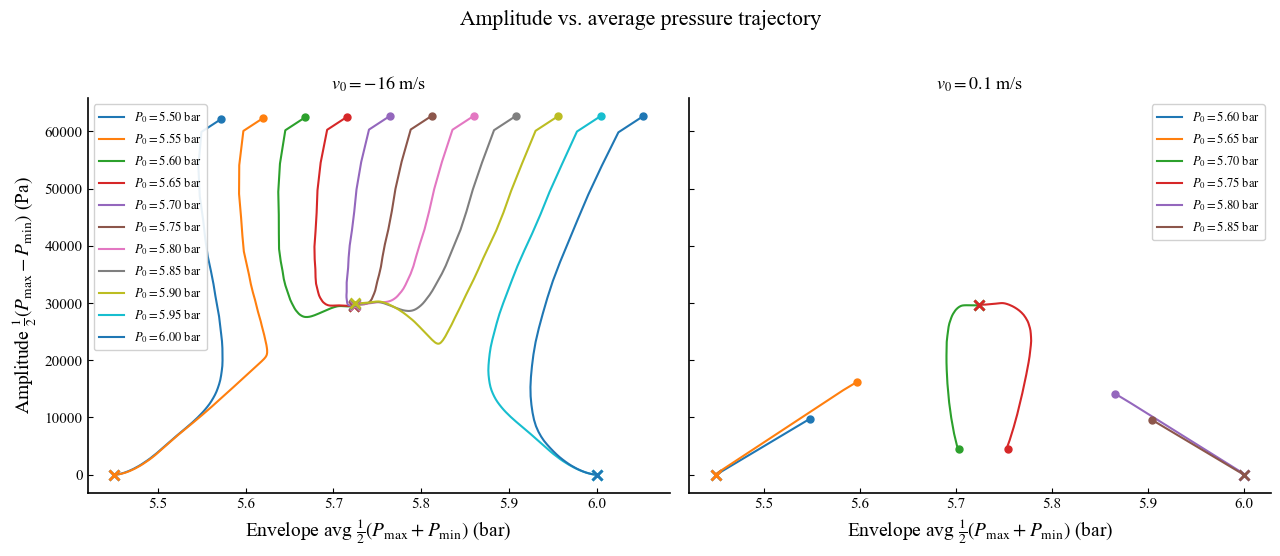

In [5]:

# ---- Plot — two subplots (one per folder), legend by P0 ----

with mpl.rc_context({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 13,
    "axes.labelsize": 14,
    "axes.titlesize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

    folder_labels = list(data.keys())

    for ax, label in zip(axes, folder_labels):
        runs = data[label]
        prop_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]

        for i, (P0, idx, avg, amp) in enumerate(runs):
            color = prop_cycle[i % len(prop_cycle)]
            ax.plot(avg / 1e5, amp, color=color, lw=1.5,
                    label=f"$P_0 = {P0/1e5:.2f}$ bar")
            ax.plot(avg[0]  / 1e5, amp[0],  "o", color=color, ms=5, zorder=5)
            ax.plot(avg[-1] / 1e5, amp[-1], "x", color=color, ms=7, mew=2, zorder=5)

        ax.set_title(label)
        ax.set_xlabel(r"Envelope avg $\frac{1}{2}(P_{\max}+P_{\min})$ (bar)")
        ax.legend(fontsize=9, framealpha=0.9, ncol=1)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[0].set_ylabel(r"Amplitude $\frac{1}{2}(P_{\max}-P_{\min})$ (Pa)")

    fig.suptitle("Amplitude vs. average pressure trajectory", y=1.01)
    plt.tight_layout()

    save_path = os.path.join(base, "amplitude_vs_avg_trajectory.pdf")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved to {save_path}")
    plt.show()
